<a href="https://www.kaggle.com/code/mukeshkumar95/decision-boundary-of-a-perceptron-on-iris-data?scriptVersionId=366481699" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.linear_model import Perceptron

iris=load_iris(as_frame=True)
X=iris.data[["petal length (cm)", "petal width (cm)"]].values
y=(iris.target==0) #Iris setosa

In [3]:
per_clf=Perceptron(random_state=42)
per_clf.fit(X,y)

Perceptron(random_state=42)

In [4]:
X_new=[[2,0.5],[3,1]]
y_pred=per_clf.predict(X_new) #predicts true or false for these 2 flowers

In [5]:
y_pred

array([ True, False])

The Perceptron is equivalent to a SGDClassifier with loss ="perceptron", no regularization, and a constant learning rate equal to 1.

In [6]:
#building and training a perceptron
from sklearn.linear_model import SGDClassifier

sgd_clf=SGDClassifier(loss="perceptron", penalty=None,
                     learning_rate="constant",eta0=1, random_state=42)

sgd_clf.fit(X,y)
assert(sgd_clf.coef_ == per_clf.coef_).all()
assert(sgd_clf.intercept_== per_clf.intercept_).all()

When the Perceptron finds a decision boundary that properly separates the classes, it stops learning. This means that the decision boundary is often quite close to one class.

In [7]:
#plotting the decision boundary of a perceptron on the iris dataset.

from matplotlib.colors import ListedColormap

a=-per_clf.coef_[0,0]/per_clf.coef_[0,1]
b=-per_clf.intercept_/per_clf.coef_[0,1]

axes=[0,5,0,2]
x0,x1=np.meshgrid(
    np.linspace(axes[0],axes[1], 500).reshape(-1,1),
    np.linspace(axes[2], axes[3],200).reshape(-1,1),
)

In [8]:
X_new=np.c_[x0.ravel(), x1.ravel()]
y_predict=per_clf.predict(X_new)

zz=y_predict.reshape(x0.shape)
custom_cmap=ListedColormap(['#9898ff','#fafab0'])


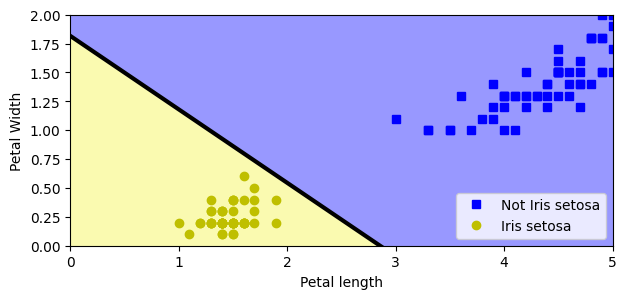

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,3))
plt.plot(X[y==0,0], X[y==0,1],"bs",label="Not Iris setosa")
plt.plot(X[y==1,0],X[y==1,1],"yo",label="Iris setosa")
plt.plot([axes[0], axes[1]],[a * axes[0]+b, a*axes[1]+b],"k-",linewidth=3)
plt.contourf(x0,x1,zz, cmap=custom_cmap)
plt.xlabel("Petal length")
plt.ylabel("Petal Width")
plt.legend(loc="lower right")
plt.axis(axes)
plt.show()